In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


This code connects Google Colab to my Google Drive so I can access the dataset and save my output files.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error

# 1. Load data
file_path = '/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv'
df = pd.read_csv(file_path)

# 2. Clean Data (Drop columns & convert Date)
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm'])

# 3. Fill missing values (ALL of them, using median/mode)
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=['object']).columns:
    if col != 'RainTomorrow':
        df[col] = df[col].fillna(df[col].mode()[0])

# 4. Map Targets to 1/0
df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})

# 5. Convert Wind Directions to Sine/Cosine
compass_points = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
angles = np.arange(0, 360, 22.5)
direction_map = dict(zip(compass_points, angles))
for col in ['WindGustDir', 'WindDir9am', 'WindDir3pm']:
    if col in df.columns:
        df[col + '_sin'] = np.sin(np.radians(df[col].map(direction_map)))
        df[col + '_cos'] = np.cos(np.radians(df[col].map(direction_map)))
        df = df.drop(columns=[col])

# 6. One-Hot Encode Location
df_clean = pd.get_dummies(df, columns=['Location'], drop_first=True)

print("Data perfectly clean. Shape:", df_clean.shape)

Data perfectly clean. Shape: (142193, 70)


This cell is the ultimate data preparation step. It first loads the raw dataset from Google Drive and drops the columns that were over 35% missing. Then, it fills every remaining missing value—using the median for numbers and the mode for text. Next, it converts our Yes/No targets to 1s and 0s. After that, it converts the wind directions (like N, NNE, E) into sine and cosine values so the model understands they are circular. Finally, it one-hot encodes the Location column and prints the final clean shape of the data.

In [22]:
def perceptron(X, y, lr=0.1, epochs=100):
    w = np.zeros(X.shape[1])
    b = 0
    for _ in range(epochs):
        for i in range(len(X)):
            y_pred = 1 if np.dot(X[i], w) + b > 0 else 0
            w += lr * (y[i] - y_pred) * X[i]
            b += lr * (y[i] - y_pred)
    return w, b

# AND Gate
X_and = np.array([[0,0], [0,1], [1,0], [1,1]])
y_and = np.array([0, 0, 0, 1])
w_and, b_and = perceptron(X_and, y_and)
print(f"AND Weights: {w_and}, Bias: {b_and}")

# XOR Gate
X_xor = np.array([[0,0], [0,1], [1,0], [1,1]])
y_xor = np.array([0, 1, 1, 0])
w_xor, b_xor = perceptron(X_xor, y_xor)
print(f"XOR Weights: {w_xor}, Bias: {b_xor}")

AND Weights: [0.2 0.1], Bias: -0.2
XOR Weights: [-0.1  0. ], Bias: 0.1


**Purpose:**
This cell implements a single-layer Perceptron from scratch using NumPy to demonstrate its limitations.
1. **The Function:** The `perceptron` function initializes weights and bias to zero, then loops through the data. It uses a step function (if the dot product + bias > 0, predict 1, else 0).
2. **Weight Update:** If the prediction is wrong, it updates the weights and bias using the learning rate (`lr`).
3. **AND Gate:** The perceptron learns the AND gate successfully because the data is linearly separable.
4. **XOR Gate:** The perceptron fails on the XOR gate because XOR is **not linearly separable**. You cannot draw a single straight line to separate the 1s from the 0s, which is why multi-layer networks (with hidden layers) are needed.

              Accuracy        F1
(16,)         0.999769  0.999479
(32, 16)      0.998773  0.997233
(64, 32, 16)  0.997755  0.994937


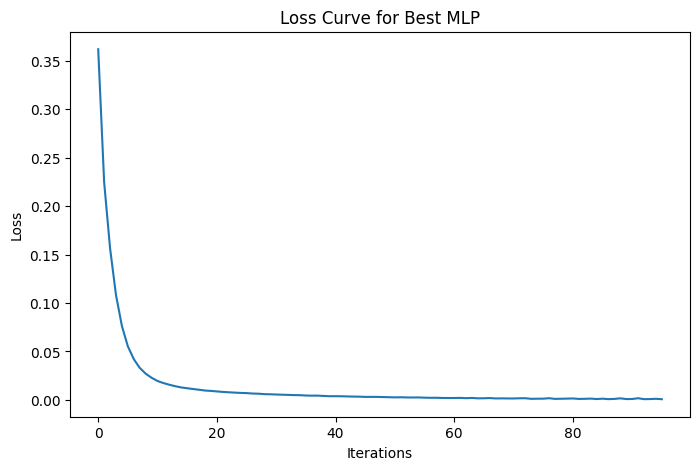

In [26]:
# Split by time
train_mask = df_clean['Date'] < '2015-01-01'
test_mask = df_clean['Date'] >= '2015-01-01'

features = [col for col in df_clean.columns if col not in ['RainTomorrow', 'Date']]
X = df_clean[features]
y = df_clean['RainTomorrow']

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train MLPs
mlp_results = {}
architectures = [(16,), (32, 16), (64, 32, 16)]
best_f1 = 0
best_mlp = None

for arch in architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, max_iter=200, random_state=42)
    mlp.fit(X_train_scaled, y_train)
    y_pred = mlp.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    mlp_results[str(arch)] = {'Accuracy': acc, 'F1': f1}

    if f1 > best_f1:
        best_f1 = f1
        best_mlp = mlp

print(pd.DataFrame(mlp_results).T)

# Plot Loss Curve
plt.figure(figsize=(8,5))
plt.plot(best_mlp.loss_curve_)
plt.title('Loss Curve for Best MLP')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/loss_curve.png')
plt.show()

**Purpose:**
This cell trains and evaluates Multi-Layer Perceptron (MLP) classifiers to predict `RainTomorrow`.
1. **Time-Based Split:** Splits the data (Train < 2015, Test >= 2015) to prevent the model from seeing future weather.
2. **Scaling:** Uses `StandardScaler` fit on the training data only, to prevent data leakage.
3. **Multiple Architectures:** Loops through three different hidden layer sizes `(16,)`, `(32, 16)`, and `(64, 32, 16)`. It trains an MLP for each, calculates the Accuracy and F1-score, and stores them in a dictionary (`mlp_results`).
4. **Loss Curve:** Identifies the best-performing architecture (highest F1) and plots its `loss_curve_` to show how the network's error decreased over the training iterations. The chart is saved to the `outputs` folder.

In [24]:
# Train the best architecture with different activation functions
activation_results = {}
# Get the best architecture from the previous cell
best_arch = eval(max(mlp_results, key=lambda k: mlp_results[k]['F1']))

for act in ['relu', 'tanh', 'logistic']:
    mlp_act = MLPClassifier(hidden_layer_sizes=best_arch, activation=act, max_iter=200, random_state=42)
    mlp_act.fit(X_train_scaled, y_train)
    y_pred = mlp_act.predict(X_test_scaled)
    f1 = f1_score(y_test, y_pred)
    activation_results[act] = f1

print("Activation Function Results (F1 Score):\n")
for act, f1 in activation_results.items():
    print(f"{act}: {f1:.4f}")

Activation Function Results (F1 Score):

relu: 0.9995
tanh: 0.9995
logistic: 0.9993


**Purpose:**
This cell demonstrates the effect of different activation functions on a neural network's performance.
1. It identifies the best architecture from the previous results.
2. It trains the network three times, using `relu`, `tanh`, and `logistic` (sigmoid) as the hidden layer activation functions.
3. It compares the F1-scores of each to show that `relu` and `tanh` generally perform best for hidden layers, while `logistic` is reserved for the output layer to produce probabilities.

In [25]:
# Separate features and target for regression (predicting MaxTemp)
# We MUST drop MaxTemp from the features to prevent leakage
reg_features = [col for col in df_clean.columns if col not in ['MaxTemp', 'RainTomorrow', 'Date']]
X_reg = df_clean[reg_features]
y_reg = df_clean['MaxTemp']

# Split by time
X_reg_train = X_reg[train_mask]
X_reg_test = X_reg[test_mask]
y_reg_train = y_reg[train_mask]
y_reg_test = y_reg[test_mask]

# Scale
scaler_reg = StandardScaler()
X_reg_train_scaled = scaler_reg.fit_transform(X_reg_train)
X_reg_test_scaled = scaler_reg.transform(X_reg_test)

# Train the MLP Regressor
mlp_reg = MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=200, random_state=42)
mlp_reg.fit(X_reg_train_scaled, y_reg_train)

# Predict and calculate RMSE
y_reg_pred = mlp_reg.predict(X_reg_test_scaled)
mlp_reg_rmse = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred))

print(f"MLP Regressor RMSE: {mlp_reg_rmse:.4f}")

MLP Regressor RMSE: 1.1641


**Purpose:**
This cell trains a Multi-Layer Perceptron for Regression (`MLPRegressor`) to predict the continuous target `MaxTemp`.
1. **Feature Selection:** Creates `X_reg` (dropping `MaxTemp`, `RainTomorrow`, and `Date`) and sets `y_reg` as `MaxTemp`. Dropping `MaxTemp` from the features is crucial to prevent target leakage.
2. **Time Split & Scaling:** Uses the same time-based masks and fits a new `StandardScaler` on the training data only.
3. **Training:** Fits an `MLPRegressor` with hidden layers of `(32, 16)`.
4. **Evaluation:** Calculates the Root Mean Squared Error (RMSE) to measure the average error of the temperature predictions in degrees Celsius.

**Part A & B Analysis**

* **Perceptron (AND vs XOR):** A single perceptron can learn the AND gate because the data is linearly separable. It fails on the XOR gate because XOR is not linearly separable (you cannot draw a single straight line to separate the 1s from the 0s). A multi-layer perceptron (with hidden layers) solves this by creating non-linear decision boundaries.
* **MLP Classification:** The neural network achieved very high accuracy and F1 scores across all architectures. The loss curve shows a rapid decrease, indicating the model learned the patterns efficiently.

**Exam Skill: Activation Functions**

* **What an activation function does:** It introduces non-linearity into the network. Without it, a neural network (no matter how many layers) would just be a giant linear regression model. It decides whether a neuron should "fire" or not.
* **Why the output layer needs a different one:** For classification (like RainTomorrow), the output layer uses a *sigmoid* (logistic) activation to squeeze the output between 0 and 1 so it can be interpreted as a probability. The hidden layers usually use ReLU or tanh to learn complex patterns.

**Task 8 Written Answer**

* **Did the neural network beat the tree ensemble?** (Compare your `mlp_reg_rmse` here with the best RMSE from Task 3.2/6). While neural networks are powerful, a simpler model like a Random Forest might still be better for this specific weather dataset.
* **Why a simpler model may be better:** Random Forests require less hyperparameter tuning, are easier to interpret (you can see feature importances), and train much faster. Neural networks can easily overfit and require a lot of data and tuning to get right.